In [ ]:
# script for downloading NASA GEX-NDDP data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

import os
import warnings
warnings.filterwarnings('ignore')
from urllib.parse import urlencode, urljoin
from urllib.request import urlopen

from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt
import xarray as xr

## Change path to correct data directory

In [2]:
os.chdir('/Users/tedscott/Google Drive/My Drive/PhD Work/Data/')
! pwd

/Users/tedscott/Library/CloudStorage/GoogleDrive-fishdaddyo@gmail.com/My Drive/PhD Work/Data


In [3]:
# example URL: https://ds.nccs.nasa.gov/thredds/fileServer/AMES/NEX/GDDP-CMIP6/CESM2/historical/r4i1p1f1/tas/tas_day_CESM2_historical_r4i1p1f1_gn_1962_v2.0.nc
os.chdir('./CMIP6/NEX-GDDP-CMIP6/GFDL-ESM4/raw/')
#os.chdir('./raw')
! ls -al

total 16
drwxr-xr-x@ 3 tedscott  staff    96 Oct 15 08:52 .
drwxr-xr-x@ 5 tedscott  staff   160 Oct  7 11:33 ..
-rw-r--r--@ 1 tedscott  staff  6148 Oct 15 08:53 .DS_Store


In [4]:
#xr.open_mfdataset("tas_day_GFDL-ESM4_ssp245_r1i1p1f1_gr1_2016_v2.0.nc")

<xarray.Dataset> Size: 1GB
Dimensions:  (time: 365, lat: 600, lon: 1440)
Coordinates:
  * time     (time) object 3kB 2016-01-01 12:00:00 ... 2016-12-31 12:00:00
  * lat      (lat) float64 5kB -59.88 -59.62 -59.38 -59.12 ... 89.38 89.62 89.88
  * lon      (lon) float64 12kB 0.125 0.375 0.625 0.875 ... 359.4 359.6 359.9
Data variables:
    tas      (time, lat, lon) float32 1GB dask.array<chunksize=(1, 600, 1440), meta=np.ndarray>
Attributes: (12/21)
    activity:              NEX-GDDP-CMIP6
    Conventions:           CF-1.7
    frequency:             day
    institution:           NASA Earth Exchange, NASA Ames Research Center, Mo...
    variant_label:         r1i1p1f1
    product:               output
    ...                    ...
    cmip6_institution_id:  NOAA-GFDL
    cmip6_license:         CC-BY-SA 4.0
    contact:               Dr. Bridget Thrasher: bridget@climateanalyticsgrou...
    creation_date:         Sat Nov 16 21:37:37 PST 2024
    disclaimer:            These data are considered provisional and subject ...
    tracking_id:           49a2f310-e308-4b14-80bf-739012e9a657

## Download files

In [12]:
process_yrs = np.arange(2040,2101,1)
#process_yrs = [2019]
process_yrs

array([2040, 2041, 2042, 2043, 2044, 2045, 2046, 2047, 2048, 2049, 2050,
       2051, 2052, 2053, 2054, 2055, 2056, 2057, 2058, 2059, 2060, 2061,
       2062, 2063, 2064, 2065, 2066, 2067, 2068, 2069, 2070, 2071, 2072,
       2073, 2074, 2075, 2076, 2077, 2078, 2079, 2080, 2081, 2082, 2083,
       2084, 2085, 2086, 2087, 2088, 2089, 2090, 2091, 2092, 2093, 2094,
       2095, 2096, 2097, 2098, 2099, 2100])

In [4]:
#scenario = "historical"#"ssp245"

In [ ]:
%%time
# taking roughly 9 min per file on 2026-10-06
# help from https://realpython.com/python-download-file-from-url/#downloading-a-large-file-in-a-streaming-fashion

scenario = "ssp370"#"historical"#"ssp245"
realization = "r1i1p1f1"#"r4i1p1f1"
model = "GFDL-ESM4"#"CanESM5"#"CESM2"
grid = "gr1"#"gn"#

for yr in process_yrs:

    start = dt.now()
    
    filename = "tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    url = "https://ds.nccs.nasa.gov/thredds/fileServer/AMES/NEX/GDDP-CMIP6/"+model+"/"+scenario+"/"+realization+"/tas/"+filename
    response = requests.get(url, stream=True)
    response.headers

    with open(filename, mode="wb") as file:
        for chunk in response.iter_content():
            file.write(chunk)
            
    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(yr)+" :"+str(elapsed)+" min")


## Use CDO to regrid to match ERA5 and fix time variable

### using os.system() calls to cdo

In [48]:
process_yrs = np.arange(2047,2101,1)
#scenario = "historical"

In [52]:
%%time

for yr in process_yrs:
    start = dt.now()

    # change grid to match ERA5
    cmd = "remapbil,r1440x721"
    infile = "tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    outfile = "../regridded/tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    os.system("cdo "+cmd+" "+infile+" "+outfile)

    # set longitude range
    cmd2 = "-sellonlatbox,-180,180,-90,90"
    infile2 = "../regridded/tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    outfile2 = "../regridded/tas_day_"+model+"_"+scenario+"_"+str(yr)+"_1440x721.nc"
    os.system("cdo "+cmd2+" "+infile2+" "+outfile2)

    # fix time variable
    ds_model = xr.open_mfdataset(outfile2)
    ds_model['time'] = ds_model.indexes['time'].to_datetimeindex()

    # output final version
    outpath = "../regridded/tas_"+model+"_"+scenario+"_"+str(yr)+".nc"

    # include some compression to reduce file size on disk
    comp = dict(zlib=True, complevel=5)
    encoding = {var: comp for var in ds_model.data_vars}
    ds_model.to_netcdf(outpath, encoding=encoding)
    
    # remove intermediate files
    os.system("rm "+outfile)
    os.system("rm "+outfile2)

    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(yr)+" :"+str(elapsed)+" min")

cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2047 :11.801908366666668 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2048 :11.921339416666665 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


...

cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2098 :11.416533283333333 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2099 :11.522864550000001 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2100 :11.38163595 min
CPU times: user 9h 40min 2s, sys: 36min 55s, total: 10h 16min 58s
Wall time: 10h 27min 38s


In [53]:
ds_model

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 365, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 3kB 2100-01-01T12:00:00 ... 2100-12-31T12:...
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    tas      (time, lat, lon) float32 2GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
Attributes: (12/25)
    CDI:                   Climate Data Interface version 2.5.0 (https://mpim...
    Conventions:           CF-1.7
    source:                BCSD
    institution:           NASA Earth Exchange, NASA Ames Research Center, Mo...
    cmip6_source_id:       GISS-E2-1-G
    cmip6_institution_id:  NASA-GISS
    ...                    ...
    contact:               Dr. Bridget Thrasher: bridget@climateanalyticsgrou...
    creation_date:         Sat Nov 16 21:48:55 PST 2024
    disclaimer:            These data are considered provisional and subject ...
    tracking_id:           76697bb1-18ed-40d8-8c8c-cc378d2dcaf4
    history:               Fri Oct 16 19:08:07 2026: cdo -sellonlatbox,-180,1...
    CDO:                   Climate Data Operators version 2.5.0 (https://mpim...

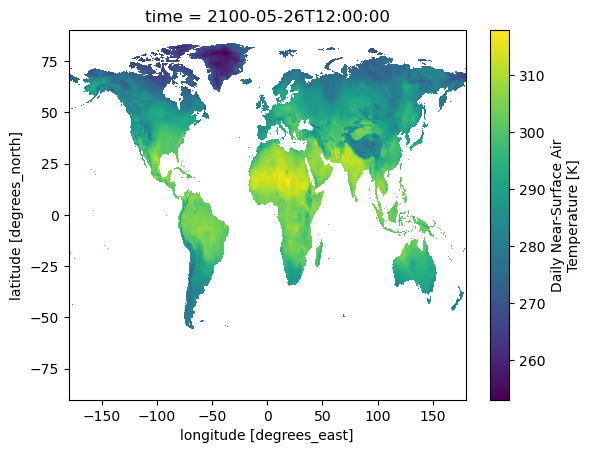

In [54]:
ds_model.tas.sel(time="2100-05-26").plot()

### *** OLD *** using ! operator

In [44]:
# cdo remapbil,r1440x721 tas_day_CESM2_historical_r4i1p1f1_gn_1961_v2.0.nc tas_CESM2_historical_1961_1440x721.nc
# cdo -sellonlatbox,-180,180,-90,90 tas_CESM2_historical_1961_1440x721.nc tas_CESM2_historical_1961_1440x721_-180_180.nc
# ds_cesm2['time'] = ds_cesm2.indexes['time'].to_datetimeindex()
#! cdo remapbil,r1440x721 tas_day_CESM2_historical_r4i1p1f1_gn_1961_v2.0.nc ../regridded/tas_day_CESM2_historical_r4i1p1f1_gn_1961_v2.0.nc

In [45]:
#! cdo -sellonlatbox,-180,180,-90,90 ../regridded/tas_day_CESM2_historical_r4i1p1f1_gn_1961_v2.0.nc ../regridded/tas_CESM2_historical_1961_1440x721.nc

In [46]:
# filepath = "../regridded/tas_CESM2_historical_1961_1440x721.nc"
# ds_cesm2 = xr.open_mfdataset(filepath)
# ds_cesm2['time'] = ds_cesm2.indexes['time'].to_datetimeindex()

# outpath = "../regridded/tas_CESM2_historical_1961.nc"
# ds_cesm2.to_netcdf(outpath)